# Seven-Day Environmental Risk Forecast Demo

This notebook runs the saved Black and Yellow Sigatoka models on a simulated hourly weather scenario. It does not forecast weather or train models.

## 1. Import Libraries

In [1]:
# Import libraries
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



## 2. Load Weather Data

Create reproducible simulated history and future hourly weather, save both files, and read them back. They are examples, not sensor readings or a provider forecast.

In [2]:
# Create simulated hourly example data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEMO_DIR = PROJECT_ROOT / "forecast_demo"
DEMO_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(20261020)
total_hours = 336 + 168
hour_number = np.arange(total_hours)
daily_temperature_change = np.repeat(rng.normal(0, 1.1, 21), 24)
temperature = (
    27.0
    + 2.2 * np.sin(2 * np.pi * (hour_number % 24 - 8) / 24)
    + daily_temperature_change
    + rng.normal(0, 0.65, total_hours)
)
temperature = np.clip(temperature, 17.1, 33.8)

# Generate varied wet and dry periods with a fixed seed
wetness = np.zeros(total_hours, dtype=int)
wet_state = 0
for hour in range(total_hours):
    if wet_state == 1:
        wet_state = int(rng.random() < 0.78)
    else:
        wet_state = int(rng.random() < 0.18)
    wetness[hour] = wet_state

timestamps = pd.date_range("2026-10-06 01:00", periods=total_hours, freq="h", tz="UTC")
weather_data = pd.DataFrame({
    "timestamp": timestamps.strftime("%Y-%m-%dT%H:%M:%SZ"),
    "air_temp_c": np.round(temperature, 3),
    "estimated_leaf_wet": wetness,
})
history_path = DEMO_DIR / "history_336h.csv"
future_path = DEMO_DIR / "future_168h.csv"

# Add a comment line so each CSV is clearly marked as simulated
for path, frame, label in [
    (history_path, weather_data.iloc[:336], "336-hour simulated historical example"),
    (future_path, weather_data.iloc[336:], "168-hour simulated future example"),
]:
    with path.open("w", encoding="utf-8", newline="") as csv_file:
        csv_file.write(f"# SIMULATED DATA - {label}; NOT SENSOR OR PROVIDER FORECAST DATA\n")
        frame.to_csv(csv_file, index=False)

# Read the hourly weather records
history_df = pd.read_csv(history_path, comment="#")
future_df = pd.read_csv(future_path, comment="#")
print("Created:", history_path)
print("Created:", future_path)
print("History rows:", len(history_df), "Future rows:", len(future_df))


Created: C:\Users\HP\Desktop\ML training\forecast_demo\history_336h.csv
Created: C:\Users\HP\Desktop\ML training\forecast_demo\future_168h.csv
History rows: 336 Future rows: 168


## 3. Check Hourly Records

Check the record counts, timestamps, input values, and transition from history to future. No missing values are filled.

In [3]:
# Check hourly data
expected_columns = ["timestamp", "air_temp_c", "estimated_leaf_wet"]
history_df["timestamp"] = pd.to_datetime(history_df["timestamp"], utc=True, errors="coerce")
future_df["timestamp"] = pd.to_datetime(future_df["timestamp"], utc=True, errors="coerce")

checks = []
for name, frame, expected_rows in [("History", history_df, 336), ("Future", future_df, 168)]:
    differences = frame["timestamp"].diff().dropna()
    checks.extend([
        [name, "Expected row count", len(frame) == expected_rows],
        [name, "Expected columns", frame.columns.tolist() == expected_columns],
        [name, "Chronological hourly timestamps", bool((differences == pd.Timedelta(hours=1)).all())],
        [name, "No duplicate timestamps", not frame["timestamp"].duplicated().any()],
        [name, "No missing timestamps or input values", not frame.isna().any().any()],
        [name, "Finite numeric temperatures", bool(np.isfinite(frame["air_temp_c"].to_numpy(dtype=float)).all())],
        [name, "Wetness is binary 0/1", bool(frame["estimated_leaf_wet"].isin([0, 1]).all())],
        [name, "Both wet and dry periods present", frame["estimated_leaf_wet"].nunique() == 2],
    ])

checks.extend([
    ["Both", "No history/future timestamp overlap", history_df["timestamp"].max() < future_df["timestamp"].min()],
    ["Both", "Future starts one hour after history", future_df["timestamp"].iloc[0] == history_df["timestamp"].iloc[-1] + pd.Timedelta(hours=1)],
    ["Both", "Continuous history-to-future hours", future_df["timestamp"].iloc[0] - history_df["timestamp"].iloc[-1] == pd.Timedelta(hours=1)],
])
record_checks = pd.DataFrame(checks, columns=["Dataset", "Check", "Passed"])
display(record_checks)
if not record_checks["Passed"].all():
    raise ValueError("Hourly weather validation failed. The example data was not repaired automatically.")

print("History temperature range:", history_df["air_temp_c"].min(), "to", history_df["air_temp_c"].max(), "C")
print("Future temperature range:", future_df["air_temp_c"].min(), "to", future_df["air_temp_c"].max(), "C")


,Dataset,Check,Passed
0,History,Expected row count,True
1,History,Expected columns,True
2,History,Chronological hourly timestamps,True
3,History,No duplicate timestamps,True
4,History,No missing timestamps or input values,True
5,History,Finite numeric temperatures,True
6,History,Wetness is binary 0/1,True
7,History,Both wet and dry periods present,True
8,Future,Expected row count,True
9,Future,Expected columns,True


History temperature range: 21.856 to 32.564 C
Future temperature range: 22.372 to 31.439 C


## 4. Load Trained Models

Use the saved models and verify their feature names and order. Black risk boundaries follow the existing final evaluation code: 0 is No Risk, values below 25 are Low, 25 to below 75 are Moderate, and 75 or above are High.

In [4]:
# Load the saved models
BLACK_MODEL_DIR = PROJECT_ROOT / "Models" / "black_sigatoka" / "random_forest"
YELLOW_MODEL_DIR = PROJECT_ROOT / "Models" / "yellow_sigatoka" / "xgboost"

black_model = joblib.load(BLACK_MODEL_DIR / "random_forest_model.joblib")
yellow_model = joblib.load(YELLOW_MODEL_DIR / "xgboost_model.joblib")
black_metadata = json.loads((BLACK_MODEL_DIR / "model_metadata.json").read_text(encoding="utf-8"))
yellow_metadata = json.loads((YELLOW_MODEL_DIR / "xgboost_metadata.json").read_text(encoding="utf-8"))

BLACK_FEATURES = ["air_temp_c", "estimated_leaf_wet", "consecutive_wetness_hours"]
YELLOW_FEATURES = ["mean_temp_previous_14d_c", "wet_hours_previous_14d", "consecutive_wetness_hours"]
assert black_metadata["feature_order"] == BLACK_FEATURES
assert yellow_metadata["features"] == YELLOW_FEATURES
assert list(black_model.feature_names_in_) == BLACK_FEATURES
assert list(yellow_model.feature_names_in_) == YELLOW_FEATURES

# Ranges are from the approved Black Sigatoka training data review
BLACK_TRAIN_RANGES = {"air_temp_c": (17.011, 33.866), "estimated_leaf_wet": (0, 1), "consecutive_wetness_hours": (0, 120)}
print("Black feature order:", BLACK_FEATURES)
print("Yellow feature order:", YELLOW_FEATURES)
print("Black training ranges:", BLACK_TRAIN_RANGES)
print("Yellow 14-day window: 336 hourly readings; temperature range 8 to 40 C, wet hours 0 to 336")
print("Black metadata thresholds:", black_metadata["risk_category_thresholds"])
print("Yellow metadata thresholds:", yellow_metadata["risk_thresholds"])


Black feature order: ['air_temp_c', 'estimated_leaf_wet', 'consecutive_wetness_hours']
Yellow feature order: ['mean_temp_previous_14d_c', 'wet_hours_previous_14d', 'consecutive_wetness_hours']
Black training ranges: {'air_temp_c': (17.011, 33.866), 'estimated_leaf_wet': (0, 1), 'consecutive_wetness_hours': (0, 120)}
Yellow 14-day window: 336 hourly readings; temperature range 8 to 40 C, wet hours 0 to 336
Black metadata thresholds: {'No Risk': 'score == 0', 'Low': '0 < score < 25', 'Moderate': '25 <= score < 75', 'High': '75 <= score <= 100'}
Yellow metadata thresholds: {'No Risk': 'score < 5', 'Low': '5 <= score < 30', 'Moderate': '30 <= score < 65', 'High': '65 <= score <= 100'}


## 5. Calculate Environmental Features

Current features use only the historical records. Future features use readings only through each forecast time. The Yellow 14-day window always contains exactly 336 readings, including the current endpoint hour.

In [5]:
# Calculate wetness streaks and Yellow rolling features
def wet_streak_ending_now(wet_values):
    streak = 0
    for value in reversed(np.asarray(wet_values, dtype=int)):
        if value == 0:
            break
        streak += 1
    return streak


def yellow_features_for_window(window):
    if len(window) != 336:
        raise ValueError("Yellow Sigatoka requires exactly 336 hourly readings.")
    return {
        "mean_temp_previous_14d_c": float(window["air_temp_c"].mean()),
        "wet_hours_previous_14d": int(window["estimated_leaf_wet"].sum()),
        "consecutive_wetness_hours": wet_streak_ending_now(window["estimated_leaf_wet"]),
    }

# Current inputs use the 336 historical records only
current_time = history_df["timestamp"].iloc[-1]
current_black_input = pd.DataFrame([{
    "air_temp_c": float(history_df["air_temp_c"].iloc[-1]),
    "estimated_leaf_wet": int(history_df["estimated_leaf_wet"].iloc[-1]),
    "consecutive_wetness_hours": wet_streak_ending_now(history_df["estimated_leaf_wet"]),
}], columns=BLACK_FEATURES)
current_yellow_values = yellow_features_for_window(history_df.tail(336))
current_yellow_input = pd.DataFrame([current_yellow_values], columns=YELLOW_FEATURES)
assert history_df["timestamp"].max() == current_time

# Make future model inputs at the end of each 24-hour forecast day
all_weather = pd.concat([history_df, future_df], ignore_index=True)
forecast_inputs = [{
    "day": "Current",
    "as_of": current_time,
    "black_input": current_black_input,
    "yellow_input": current_yellow_input,
    "history_hours_in_yellow_window": 336,
    "future_hours_in_yellow_window": 0,
}]

for day in range(1, 8):
    end_index = 335 + day * 24
    observed_to_time = all_weather.iloc[:end_index + 1]
    as_of_time = observed_to_time["timestamp"].iloc[-1]
    yellow_window = observed_to_time.tail(336)
    expected_history = 336 - day * 24
    expected_future = day * 24
    history_in_window = int((yellow_window["timestamp"] <= current_time).sum())
    future_in_window = int((yellow_window["timestamp"] > current_time).sum())

    if len(yellow_window) != 336:
        raise ValueError(f"Day {day} Yellow window does not contain 336 readings.")
    if as_of_time != yellow_window["timestamp"].max() or (yellow_window["timestamp"] > as_of_time).any():
        raise ValueError(f"Day {day} contains readings after its prediction time.")
    if history_in_window != expected_history or future_in_window != expected_future:
        raise ValueError(f"Day {day} has an unexpected historical/future window composition.")

    last_reading = observed_to_time.iloc[-1]
    black_input = pd.DataFrame([{
        "air_temp_c": float(last_reading["air_temp_c"]),
        "estimated_leaf_wet": int(last_reading["estimated_leaf_wet"]),
        "consecutive_wetness_hours": wet_streak_ending_now(observed_to_time["estimated_leaf_wet"]),
    }], columns=BLACK_FEATURES)
    yellow_input = pd.DataFrame([yellow_features_for_window(yellow_window)], columns=YELLOW_FEATURES)
    forecast_inputs.append({
        "day": f"Day {day}",
        "as_of": as_of_time,
        "black_input": black_input,
        "yellow_input": yellow_input,
        "history_hours_in_yellow_window": history_in_window,
        "future_hours_in_yellow_window": future_in_window,
    })

# Show example inputs passed to both models
feature_examples = []
for item in forecast_inputs[:2]:
    feature_examples.append({"Forecast": item["day"], **{f"Black {key}": value for key, value in item["black_input"].iloc[0].items()}, **{f"Yellow {key}": value for key, value in item["yellow_input"].iloc[0].items()}})
display(pd.DataFrame(feature_examples).set_index("Forecast").round(3))


,Black air_temp_c,Black estimated_leaf_wet,Black consecutive_wetness_hours,Yellow mean_temp_previous_14d_c,Yellow wet_hours_previous_14d,Yellow consecutive_wetness_hours
Forecast,,,,,,
Current,25.605,1.0,15.0,26.773,145.0,15.0
Day 1,26.115,0.0,0.0,26.924,146.0,0.0


## 6. Predict Current Risk

Predict current environmental suitability from the latest historical reading and historical 14-day window only.

In [6]:
# Predict current risk
black_current_raw = float(black_model.predict(current_black_input)[0])
yellow_current_raw = float(yellow_model.predict(current_yellow_input)[0])
if not np.isfinite([black_current_raw, yellow_current_raw]).all():
    raise ValueError("A current model prediction is not finite.")
print("Current prediction time:", current_time)
print("Current Black raw score:", black_current_raw)
print("Current Yellow raw score:", yellow_current_raw)


Current prediction time: 2026-10-20 00:00:00+00:00
Current Black raw score: 17.681360666666656
Current Yellow raw score: 58.65849304199219


## 7. Predict Seven-Day Risk

Each future prediction uses the available readings through that day only. The saved models do not predict weather.

In [7]:
# Predict risk scores for each forecast day
def black_risk_level(score):
    score = float(np.clip(score, 0, 100))
    if score == 0:
        return "No Risk"
    if score < 25:
        return "Low"
    if score < 75:
        return "Moderate"
    return "High"


def yellow_risk_level(score):
    score = float(np.clip(score, 0, 100))
    if score < 5:
        return "No Risk"
    if score < 30:
        return "Low"
    if score < 65:
        return "Moderate"
    return "High"

forecast_rows = []
for item in forecast_inputs:
    black_features = item["black_input"]
    yellow_features = item["yellow_input"]
    if list(black_features.columns) != BLACK_FEATURES or list(yellow_features.columns) != YELLOW_FEATURES:
        raise ValueError("Forecast features do not match the trained model feature order.")

    if item["day"] == "Current":
        black_raw = black_current_raw
        yellow_raw = yellow_current_raw
    else:
        black_raw = float(black_model.predict(black_features)[0])
        yellow_raw = float(yellow_model.predict(yellow_features)[0])
    if not np.isfinite([black_raw, yellow_raw]).all():
        raise ValueError(f"A model prediction for {item['day']} is not finite.")

    black_score = float(np.clip(black_raw, 0, 100))
    yellow_score = float(np.clip(yellow_raw, 0, 100))
    forecast_rows.append({
        "Forecast Day": item["day"],
        "As of (UTC)": item["as_of"],
        "Black Sigatoka Score": black_score,
        "Black Sigatoka Level": black_risk_level(black_score),
        "Yellow Sigatoka Score": yellow_score,
        "Yellow Sigatoka Level": yellow_risk_level(yellow_score),
    })

forecast_results = pd.DataFrame(forecast_rows)
print("Raw prediction score ranges:")
print("Black:", min(float(black_current_raw), *(float(black_model.predict(item["black_input"])[0]) for item in forecast_inputs[1:])), "to", max(float(black_current_raw), *(float(black_model.predict(item["black_input"])[0]) for item in forecast_inputs[1:])))
print("Yellow:", min(float(yellow_current_raw), *(float(yellow_model.predict(item["yellow_input"])[0]) for item in forecast_inputs[1:])), "to", max(float(yellow_current_raw), *(float(yellow_model.predict(item["yellow_input"])[0]) for item in forecast_inputs[1:])))


Raw prediction score ranges:


Black: 0.0 to 17.681360666666656
Yellow: 48.60130310058594 to 58.65849304199219


## 8. Generate Risk Alerts

Alerts are simple rules based on the predicted risk level. They do not send notifications.

In [8]:
# Generate a rule-based alert for each disease and day
alert_rules = {
    "No Risk": ("none", False, "No elevated environmental risk indicated. Continue routine monitoring."),
    "Low": ("info", False, "Slightly favourable conditions. Continue monitoring."),
    "Moderate": ("warning", True, "Moderately favourable conditions. Increase monitoring and consider field inspection."),
    "High": ("critical", True, "Highly favourable conditions. Prioritize field inspection and notify responsible staff."),
}
alert_rows = []
for _, row in forecast_results.iterrows():
    future = row["Forecast Day"] != "Current"
    for disease in ["Black Sigatoka", "Yellow Sigatoka"]:
        level = row[f"{disease} Level"]
        severity, required, message = alert_rules[level]
        if future:
            message = "Forecast environmental conditions: " + message
        alert_rows.append({
            "Forecast Day": row["Forecast Day"],
            "Disease": disease,
            "Risk Level": level,
            "Severity": severity,
            "Alert Required": required,
            "Message": message,
        })
alerts = pd.DataFrame(alert_rows)
display(alerts)


,Forecast Day,Disease,Risk Level,Severity,Alert Required,Message
0,Current,Black Sigatoka,Low,info,False,Slightly favourable conditions. Continue monit...
1,Current,Yellow Sigatoka,Moderate,warning,True,Moderately favourable conditions. Increase mon...
2,Day 1,Black Sigatoka,No Risk,none,False,Forecast environmental conditions: No elevated...
3,Day 1,Yellow Sigatoka,Moderate,warning,True,Forecast environmental conditions: Moderately ...
4,Day 2,Black Sigatoka,No Risk,none,False,Forecast environmental conditions: No elevated...
5,Day 2,Yellow Sigatoka,Moderate,warning,True,Forecast environmental conditions: Moderately ...
6,Day 3,Black Sigatoka,Low,info,False,Forecast environmental conditions: Slightly fa...
7,Day 3,Yellow Sigatoka,Moderate,warning,True,Forecast environmental conditions: Moderately ...
8,Day 4,Black Sigatoka,No Risk,none,False,Forecast environmental conditions: No elevated...
9,Day 4,Yellow Sigatoka,Moderate,warning,True,Forecast environmental conditions: Moderately ...


## 9. Forecast Results

Scores are clipped to 0?100 for the displayed application output. Risk levels use the full-precision clipped scores.

In [9]:
# Show the forecast summary
summary_table = forecast_results[[
    "Forecast Day",
    "Black Sigatoka Score",
    "Black Sigatoka Level",
    "Yellow Sigatoka Score",
    "Yellow Sigatoka Level",
]].copy()
display(summary_table.round({"Black Sigatoka Score": 2, "Yellow Sigatoka Score": 2}))

alert_summary = alerts[["Forecast Day", "Disease", "Risk Level", "Severity", "Alert Required"]]
display(alert_summary)


,Forecast Day,Black Sigatoka Score,Black Sigatoka Level,Yellow Sigatoka Score,Yellow Sigatoka Level
0,Current,17.68,Low,58.66,Moderate
1,Day 1,0.00,No Risk,50.45,Moderate
2,Day 2,0.00,No Risk,50.33,Moderate
3,Day 3,0.52,Low,48.60,Moderate
4,Day 4,0.00,No Risk,49.94,Moderate
5,Day 5,1.99,Low,53.72,Moderate
6,Day 6,1.40,Low,55.73,Moderate
7,Day 7,0.00,No Risk,53.71,Moderate


,Forecast Day,Disease,Risk Level,Severity,Alert Required
0,Current,Black Sigatoka,Low,info,False
1,Current,Yellow Sigatoka,Moderate,warning,True
2,Day 1,Black Sigatoka,No Risk,none,False
3,Day 1,Yellow Sigatoka,Moderate,warning,True
4,Day 2,Black Sigatoka,No Risk,none,False
5,Day 2,Yellow Sigatoka,Moderate,warning,True
6,Day 3,Black Sigatoka,Low,info,False
7,Day 3,Yellow Sigatoka,Moderate,warning,True
8,Day 4,Black Sigatoka,No Risk,none,False
9,Day 4,Yellow Sigatoka,Moderate,warning,True


## 10. Seven-Day Risk Graph

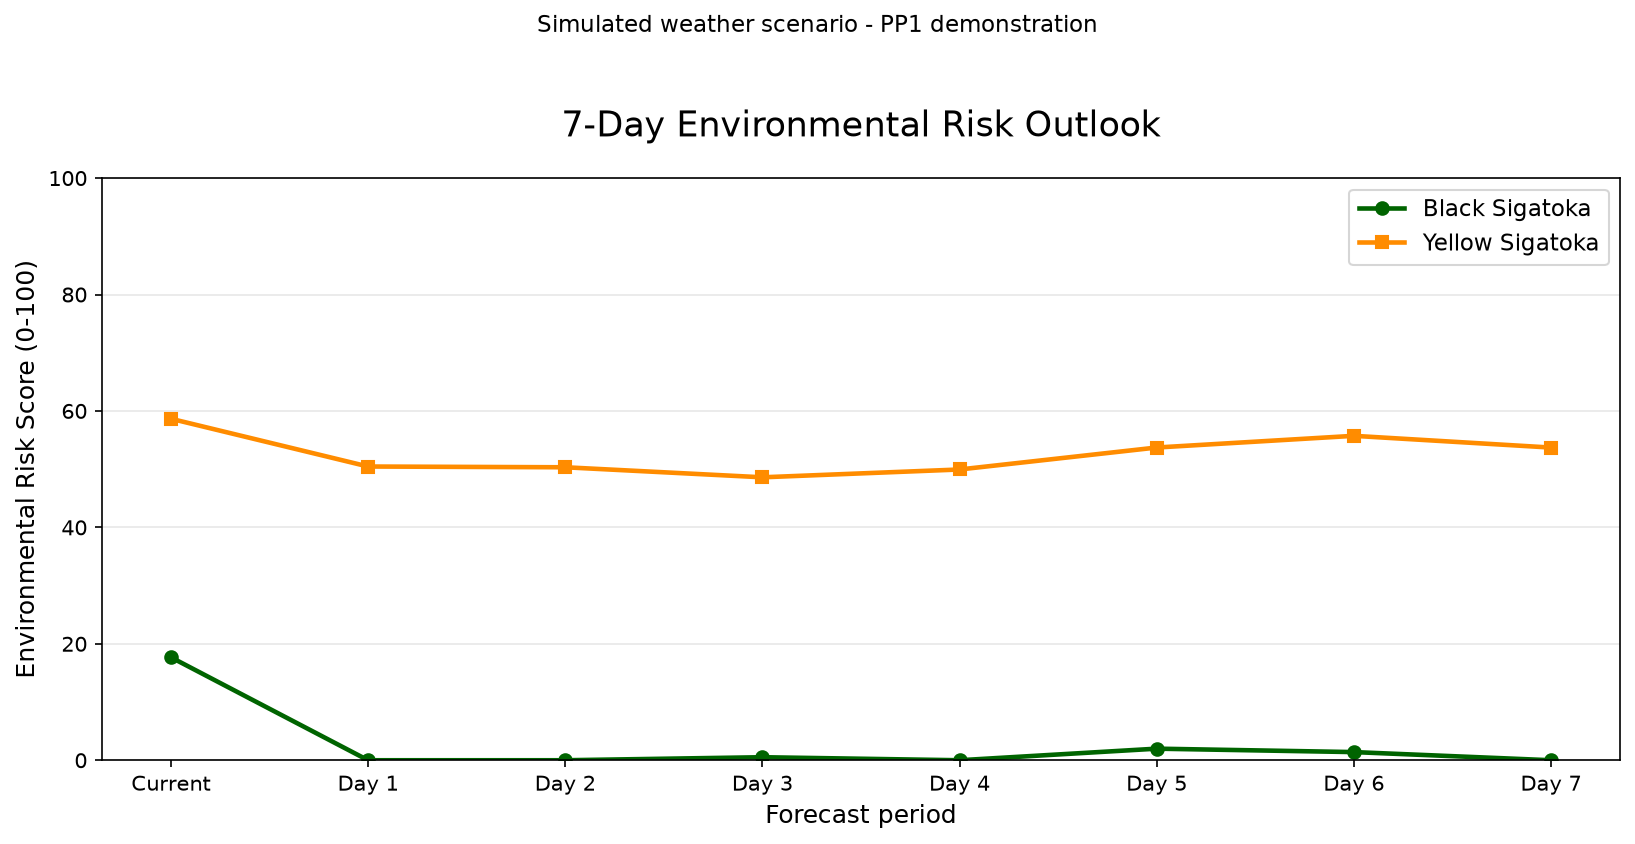

Saved graph: C:\Users\HP\Desktop\ML training\reports\forecasting\seven_day_risk_graph.png


In [10]:
# Plot the forecast
forecast_labels = summary_table["Forecast Day"]
plt.figure(figsize=(11, 6), dpi=150)
plt.plot(forecast_labels, summary_table["Black Sigatoka Score"], marker="o", linewidth=2.2, color="darkgreen", label="Black Sigatoka")
plt.plot(forecast_labels, summary_table["Yellow Sigatoka Score"], marker="s", linewidth=2.2, color="darkorange", label="Yellow Sigatoka")
plt.title("7-Day Environmental Risk Outlook", fontsize=17, pad=20)
plt.suptitle("Simulated weather scenario - PP1 demonstration", fontsize=11, y=0.93)
plt.xlabel("Forecast period", fontsize=12)
plt.ylabel("Environmental Risk Score (0-100)", fontsize=12)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=11)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.90])
GRAPH_DIR = PROJECT_ROOT / "reports" / "forecasting"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)
graph_path = GRAPH_DIR / "seven_day_risk_graph.png"
plt.savefig(graph_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved graph:", graph_path)


## 11. Limitations

Both weather sequences are simulated. Current risk uses historical readings only; future risk uses the supplied simulated future hours. These models estimate environmental suitability scores and do not forecast weather or predict confirmed disease infection.

In [11]:
# Check model inputs, windows, score outputs, risk boundaries, alerts, and weather response
window_checks = []
for item in forecast_inputs:
    black_features = item["black_input"]
    yellow_features = item["yellow_input"]
    window_checks.append({
        "Forecast": item["day"],
        "Yellow window has 336 readings": len(yellow_features) == 1 and item["history_hours_in_yellow_window"] + item["future_hours_in_yellow_window"] == 336,
        "Black temperature within training range": BLACK_TRAIN_RANGES["air_temp_c"][0] <= black_features["air_temp_c"].iloc[0] <= BLACK_TRAIN_RANGES["air_temp_c"][1],
        "Black wetness is binary": black_features["estimated_leaf_wet"].iloc[0] in [0, 1],
        "Black streak matches final wetness indicator": (black_features["estimated_leaf_wet"].iloc[0] == 1) == (black_features["consecutive_wetness_hours"].iloc[0] > 0),
        "Black streak within training range": BLACK_TRAIN_RANGES["consecutive_wetness_hours"][0] <= black_features["consecutive_wetness_hours"].iloc[0] <= BLACK_TRAIN_RANGES["consecutive_wetness_hours"][1],
        "Yellow mean temperature within 8 to 40 C": 8 <= yellow_features["mean_temp_previous_14d_c"].iloc[0] <= 40,
        "Yellow feature values finite": bool(np.isfinite(yellow_features.to_numpy(dtype=float)).all()),
        "Yellow wet hours valid": 0 <= yellow_features["wet_hours_previous_14d"].iloc[0] <= 336,
        "Yellow streak does not exceed wet hours": yellow_features["consecutive_wetness_hours"].iloc[0] <= yellow_features["wet_hours_previous_14d"].iloc[0],
        "Prediction scores finite and bounded": np.isfinite([forecast_results.loc[forecast_results["Forecast Day"] == item["day"], "Black Sigatoka Score"].iloc[0], forecast_results.loc[forecast_results["Forecast Day"] == item["day"], "Yellow Sigatoka Score"].iloc[0]]).all(),
    })
window_check_table = pd.DataFrame(window_checks).set_index("Forecast")
display(window_check_table)

# Confirm a dry hour resets a wet streak
assert wet_streak_ending_now([1, 1, 0, 1]) == 1
assert wet_streak_ending_now([1, 1, 1]) == 3

# Check risk level boundaries against the model evaluation conventions
assert [black_risk_level(value) for value in [0, 0.01, 24.99, 25, 74.99, 75, 100]] == ["No Risk", "Low", "Low", "Moderate", "Moderate", "High", "High"]
assert [yellow_risk_level(value) for value in [0, 4.99, 5, 29.99, 30, 64.99, 65, 100]] == ["No Risk", "No Risk", "Low", "Low", "Moderate", "Moderate", "High", "High"]

# Check that alert settings match their risk levels
for _, alert in alerts.iterrows():
    severity, required, _ = alert_rules[alert["Risk Level"]]
    assert alert["Severity"] == severity and alert["Alert Required"] == required

# Check that different weather inputs produce at least one different prediction
black_daily_scores = forecast_results["Black Sigatoka Score"].nunique()
yellow_daily_scores = forecast_results["Yellow Sigatoka Score"].nunique()
weather_response_check = black_daily_scores > 1 or yellow_daily_scores > 1
assert weather_response_check, "The simulated changing weather did not change either model prediction."

assert window_check_table.all().all()
print("All forecast input and output checks passed.")
print("Distinct daily Black scores:", black_daily_scores, "Distinct daily Yellow scores:", yellow_daily_scores)


,Yellow window has 336 readings,Black temperature within training range,Black wetness is binary,Black streak matches final wetness indicator,Black streak within training range,Yellow mean temperature within 8 to 40 C,Yellow feature values finite,Yellow wet hours valid,Yellow streak does not exceed wet hours,Prediction scores finite and bounded
Forecast,,,,,,,,,,
Current,True,True,True,True,True,True,True,True,True,True
Day 1,True,True,True,True,True,True,True,True,True,True
Day 2,True,True,True,True,True,True,True,True,True,True
Day 3,True,True,True,True,True,True,True,True,True,True
Day 4,True,True,True,True,True,True,True,True,True,True
Day 5,True,True,True,True,True,True,True,True,True,True
Day 6,True,True,True,True,True,True,True,True,True,True
Day 7,True,True,True,True,True,True,True,True,True,True


All forecast input and output checks passed.
Distinct daily Black scores: 5 Distinct daily Yellow scores: 8


In [12]:
# Save the PP1 forecast report
report_path = GRAPH_DIR / "Seven_Day_Forecast_Demo_Report.md"
forecast_lines = ["| Forecast Day | Black Score | Black Level | Yellow Score | Yellow Level |", "|---|---:|---|---:|---|"]
for _, row in summary_table.iterrows():
    forecast_lines.append(f"| {row['Forecast Day']} | {row['Black Sigatoka Score']:.2f} | {row['Black Sigatoka Level']} | {row['Yellow Sigatoka Score']:.2f} | {row['Yellow Sigatoka Level']} |")
alert_lines = ["| Forecast Day | Disease | Level | Severity | Alert required |", "|---|---|---|---|---|"]
for _, row in alerts.iterrows():
    alert_lines.append(f"| {row['Forecast Day']} | {row['Disease']} | {row['Risk Level']} | {row['Severity']} | {row['Alert Required']} |")

report_lines = [
    "# Seven-Day Environmental Risk Forecast Demo", "",
    "## 1. Objective",
    "Demonstrate how saved Black and Yellow Sigatoka models estimate environmental suitability at the current time and at seven daily forecast points.", "",
    "## 2. Data used",
    "The 336-hour history and 168-hour future series are reproducible simulated examples saved in `forecast_demo/`. The weather is not from deployed sensors or a forecast provider. The current prediction uses only the historical file.", "",
    "## 3. Forecasting method",
    "The disease models do not forecast weather. They score features calculated from the supplied weather scenario. The day 1 to day 7 points use readings through the end of each corresponding 24-hour period.", "",
    "## 4. Feature calculation",
    "Black Sigatoka uses current-hour temperature, the binary wet/dry indicator, and the wet streak ending at that hour. Yellow Sigatoka uses a rolling 336-hour window for average temperature, wet-hour count, and the streak ending at the window endpoint. A 14-day window is required because the Yellow model was trained on previous-336-hour features. The current window contains 336 historical hours; day 1 contains 312 historical plus 24 future hours; day 7 contains 168 historical plus 168 future hours. The streak continues across the historical/future boundary and resets on a dry hour.", "",
    "## 5. Models used",
    "The saved Black Sigatoka Random Forest and Yellow Sigatoka XGBoost models were loaded without retraining. Input column order was checked against each model's metadata and saved feature names.", "",
    "## 6. Prediction results",
    *forecast_lines, "",
    "## 7. Risk alerts",
    "Alerts are rule-based text for the predicted category. No SMS, email, push notification, or alert model is used.",
    *alert_lines, "",
    "## 8. Tests",
    f"- Both hourly files passed count, timestamp continuity, uniqueness, missing-value, numeric-temperature, and binary-wetness checks. Temperatures stayed within the Black training range ({BLACK_TRAIN_RANGES['air_temp_c'][0]} to {BLACK_TRAIN_RANGES['air_temp_c'][1]} C); streaks stayed within its 0 to 120 training range.",
    "- Each Yellow feature window had exactly 336 readings and ended at its prediction time. The current prediction used historical readings only.",
    "- Feature order, score bounds, category boundaries, streak reset behavior, and alert rules passed checks.",
    f"- Weather changes changed model outputs across the forecast points: Black had {black_daily_scores} distinct displayed scores; Yellow had {yellow_daily_scores}.",
    "",
    "## 9. Limitations",
    "The simulated future is a demonstration, not a weather forecast. Actual future leaf wetness must be estimated from forecast weather and later checked against local leaf-wetness sensors. The existing Black training report leaves the original streak timing semantics unresolved; this demo computes a causal streak from available past/current readings, so equivalence to the original synthetic streak convention is not established. These scores are synthetic environmental suitability levels, not infection probabilities or field-validated outcomes. Source weather windows may overlap.",
    "The Black category boundary code in the existing final evaluation differs from the task's informal wording at exactly 25 and 75: the code assigns 25 to Moderate and 75 to High. The notebook follows the existing evaluation code.",
    "",
    "## 10. Future work",
    "A live system should read historical conditions from installed sensors and obtain future weather from an external forecast provider. It must derive hourly wetness using a documented method, validate forecast gaps and timestamps, and check estimated leaf wetness against sensor measurements. FastAPI integration is a separate next step.",
]
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved report:", report_path)
print("Saved graph:", graph_path)


Saved report: C:\Users\HP\Desktop\ML training\reports\forecasting\Seven_Day_Forecast_Demo_Report.md
Saved graph: C:\Users\HP\Desktop\ML training\reports\forecasting\seven_day_risk_graph.png
